In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tarfile
import urllib.request
from pathlib import Path

# First downloading the data

In [2]:
def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents = True, exist_ok =True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets", filter = "data")
    return pd.read_csv(Path("datasets/housing/housing.csv"))
housing_full = load_housing_data()

# Analyzing the data 

In [5]:
housing_full.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
housing_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
housing_full["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [8]:
housing_full.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


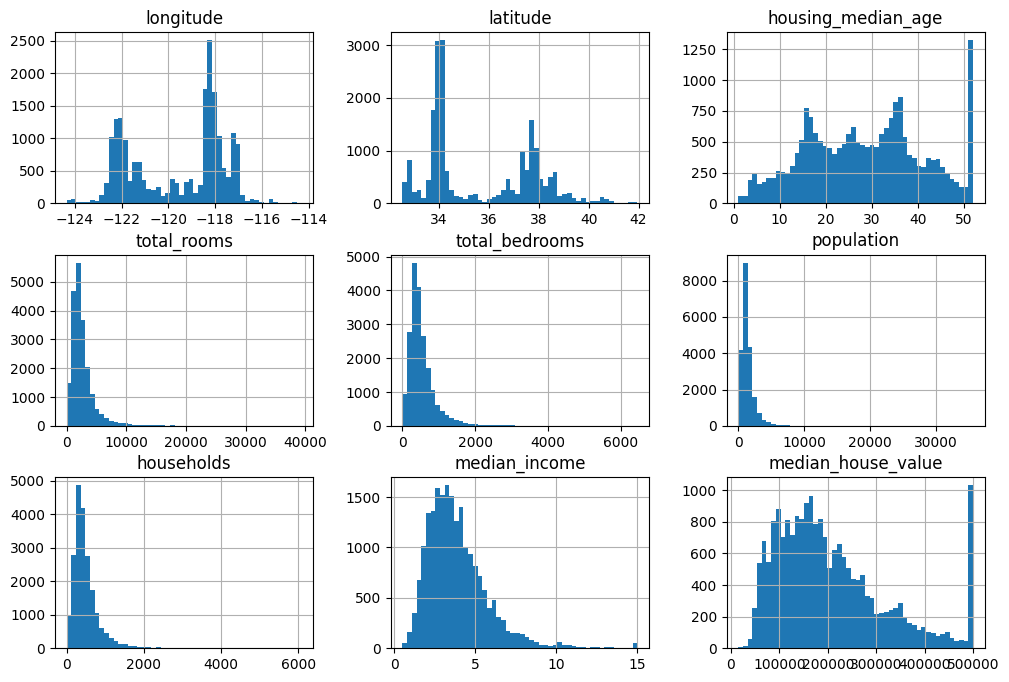

In [9]:
housing_full.hist(bins=50, figsize=(12,8))
plt.show()

# creating test data set 

In [10]:
def shuffel_and_splitdata(data,test_ratio,rng):
    shuffel_indices = rng.permutation(len(data))
    test_size = int(len(data) * test_ratio)
    test_indices = shuffel_indices[:test_size]
    train_indices = shuffel_indices[test_size:]
    return data.iloc[train_indices],data.iloc[test_indices]

In [11]:
rng = np.random.default_rng()
train_set,test_set = shuffel_and_splitdata(housing_full,0.2,rng)

In [12]:
len(train_set)

16512

In [13]:

len(test_set)

4128

In [14]:
from zlib import crc32
def is_id_in_test_set(identifier,test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data,test_ratio,id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda _id: is_id_in_test_set(_id, test_ratio))
    return data.loc[~in_test_set],data.loc[in_test_set]


In [15]:
housing_with_id = housing_full.reset_index()
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "index")

In [16]:
len(train_set)

16512

In [17]:
len(test_set)

4128

# spliting with sk learn

In [18]:
from sklearn.model_selection import train_test_split

train_set,test_set = train_test_split(housing_full,test_size=0.2,random_state=42)

In [19]:
len(train_set)

16512

In [20]:
housing_full["income_cat"] = pd.cut(housing_full["median_income"],bins=[0., 1.5, 3.0, 4.5, 6., np.inf],labels=[1, 2, 3, 4, 5])

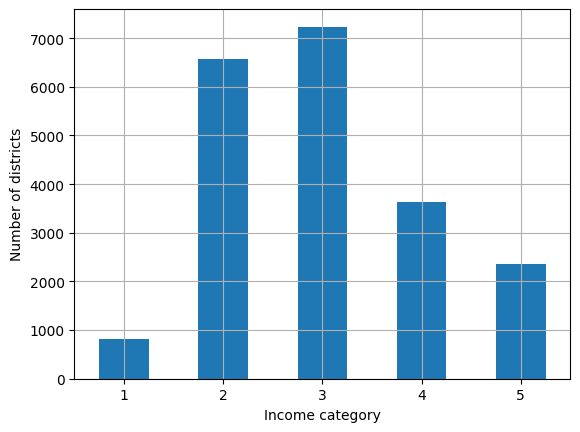

In [21]:
cat_counts = housing_full["income_cat"].value_counts().sort_index()
cat_counts.plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")
plt.show()


In [22]:
from sklearn.model_selection import StratifiedShuffleSplit

splliter = StratifiedShuffleSplit(n_splits = 10,test_size = 0.2,random_state = 42)
strat_splits = []
for train_index ,test_index in splliter.split(housing_full,housing_full["income_cat"]):
    start_train_set_n = housing_full.iloc[train_index]
    start_test_set_n = housing_full.iloc[test_index]
    strat_splits.append([start_train_set_n,start_test_set_n])



In [23]:
start_train_set, start_test_set = strat_splits[0]


In [24]:
start_test_set["income_cat"].value_counts()/len(start_test_set)

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

In [25]:
for set_ in (start_train_set, start_test_set):
    set_.drop("income_cat", axis=1, inplace=True)


C:\Users\JUNAID\AppData\Local\Temp\ipykernel_22620\3502664128.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_.drop("income_cat", axis=1, inplace=True)
C:\Users\JUNAID\AppData\Local\Temp\ipykernel_22620\3502664128.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set_.drop("income_cat", axis=1, inplace=True)


# Gaining insight

In [26]:
housing = start_train_set.copy()

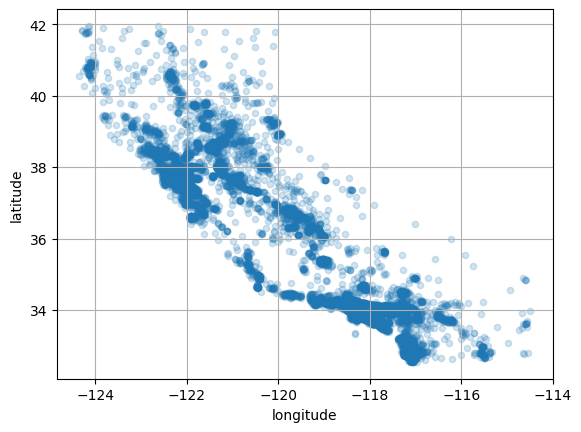

In [27]:
housing.plot(kind = "scatter",x="longitude", y="latitude", grid=True, alpha = 0.2)
plt.show()

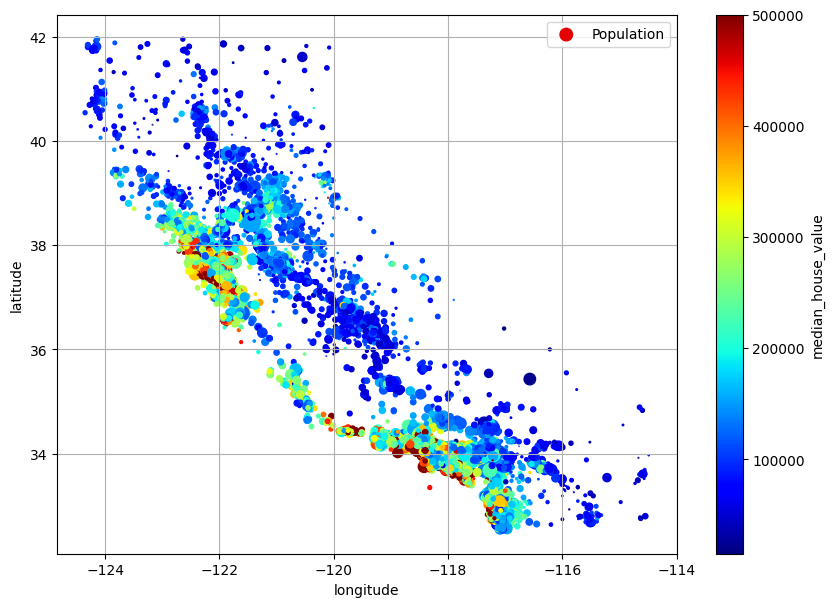

In [28]:
housing.plot(kind = "scatter",x="longitude", y="latitude",s = housing["population"]/ 100,label = "Population",
             c ="median_house_value",cmap ="jet",colorbar =True,legend = True,
             sharex = False,figsize = (10,7), grid=True)
plt.show()

In [29]:
corr_matrix = housing.corr(numeric_only= True)
corr_matrix["median_house_value"].sort_values(ascending = False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

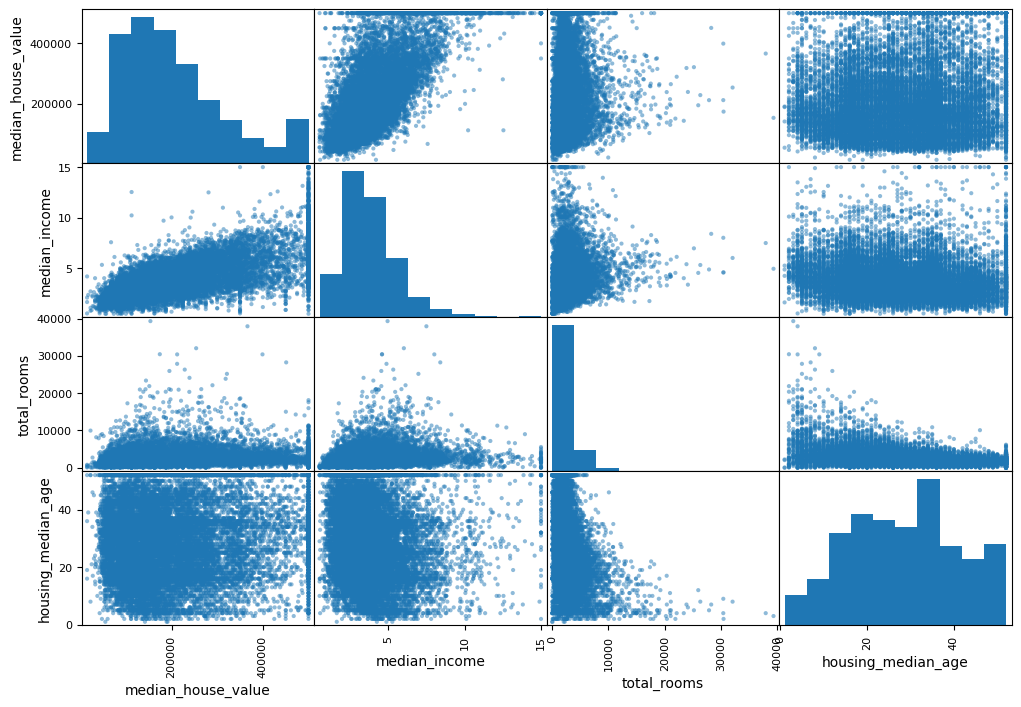

In [30]:
from pandas.plotting import scatter_matrix
attributes = ["median_house_value", "median_income", "total_rooms",
"housing_median_age"]
scatter_matrix(housing[attributes],figsize=(12,8))
plt.show()


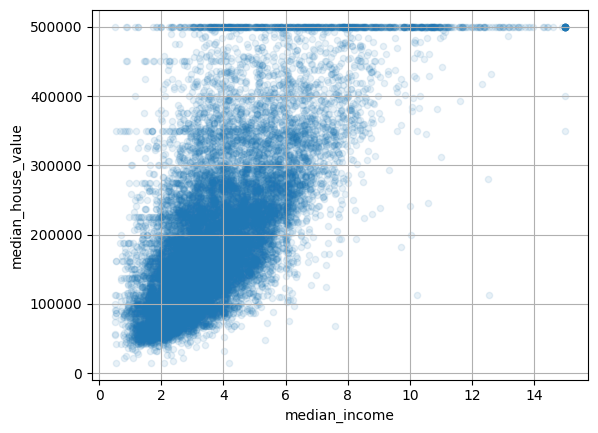

In [31]:
housing.plot(kind="scatter", x="median_income", y="median_house_value",
alpha=0.1, grid=True)
plt.show()

In [32]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]

In [33]:
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

# Preparing the data 

In [34]:
housing = start_train_set.drop("median_house_value", axis=1)
housing_labels = start_train_set["median_house_value"].copy()

In [35]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")


In [36]:
housing_num = housing.select_dtypes(include = [np.number])
imputer.fit(housing_num)

SimpleImputer(strategy='median')

In [37]:
imputer.statistics_

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [38]:
housing_num.median().values

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [39]:
X = imputer.transform(housing_num)


In [40]:
housing_cat = housing[["ocean_proximity"]]
housing_cat.head(8)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY


# to convert text housing data into num 

In [41]:
from sklearn.preprocessing import OrdinalEncoder
odn = OrdinalEncoder()
housing_cat_num = odn.fit_transform(housing_cat)


In [42]:
housing_cat_num[:8]

array([[3.],
       [0.],
       [1.],
       [1.],
       [4.],
       [1.],
       [0.],
       [3.]])

In [43]:
odn.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [44]:
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder()
housing_cat_1hot = ohe.fit_transform(housing_cat)

In [45]:
housing_cat_1hot

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16512 stored elements and shape (16512, 5)>

In [46]:
housing_cat_1hot.toarray()

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]], shape=(16512, 5))

# now scaling the data

In [47]:
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler(feature_range=(-1,1))
housing_cat_num_minmax = min_max_scaler.fit_transform(housing_num)

# implementing a radical bias funtion 

In [48]:
from sklearn.metrics.pairwise import rbf_kernel
age_simil_35 =  rbf_kernel(housing[["housing_median_age"]], [[35]], gamma=0.1)



# training a reggression model of simplicity

In [49]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
model = LinearRegression()
target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame()) 
model.fit(housing[["median_income"]],scaled_labels)
some_new_data = housing[["median_income"]].iloc[:5]

scaled_prediction = model.predict(some_new_data)
prediction = target_scaler.inverse_transform(scaled_prediction)# it works but more error pron

In [50]:
from sklearn.compose import TransformedTargetRegressor
model = TransformedTargetRegressor(LinearRegression(),
transformer=StandardScaler())
model.fit(housing[["median_income"]], housing_labels)
predictions = model.predict(some_new_data)
#simpler to use this 

# Now building a custom transformer 

In [51]:
from sklearn.preprocessing import FunctionTransformer
log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(housing[["population"]]) #Function transformner 


In [52]:
rbf_transformer = FunctionTransformer(rbf_kernel,kw_args=dict(Y=[[35.]],gamma =0.1))
age_simil_35 = rbf_transformer.transform(housing[["housing_median_age"]])

In [53]:
# cutom transformer of standerd scaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted
class StandardScalerClone(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True): # no *args or **kwargs!
        self.with_mean = with_mean
    def fit(self, X, y=None): # y is required even though we don't use it
        X = check_array(X) # checks that X is an array with finite float values
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.n_features_in_ = X.shape[1] # every estimator stores this in fit()
        return self # always return self!
    def transform(self, X):
        check_is_fitted(self) # looks for learned attributes (with trailing _)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_

In [54]:
#custom transformer for k mean 
from sklearn.cluster import KMeans
class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state
    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self # always return self!
    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)
    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

In [55]:
#using the custom transformer
custom_simil = ClusterSimilarity(n_clusters=10,gamma= 0.1,random_state=42)
similarity = custom_simil.fit_transform(housing[["latitude","longitude"]])

c:\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        

In [56]:
similarity[:3],round(2)

(array([[0.9249194 , 0.04068242, 0.77815951, 0.00450393, 0.2250272 ,
         0.42866594, 0.49304523, 0.99767913, 0.17286125, 0.01812159],
        [0.12060577, 0.99571425, 0.04939683, 0.69717984, 0.72463528,
         0.42833508, 0.00237098, 0.05129444, 0.80218931, 0.90155783],
        [0.89858907, 0.03655549, 0.9229067 , 0.00399713, 0.18647763,
         0.45853466, 0.59584955, 0.96906232, 0.17375473, 0.01748419]]),
 2)

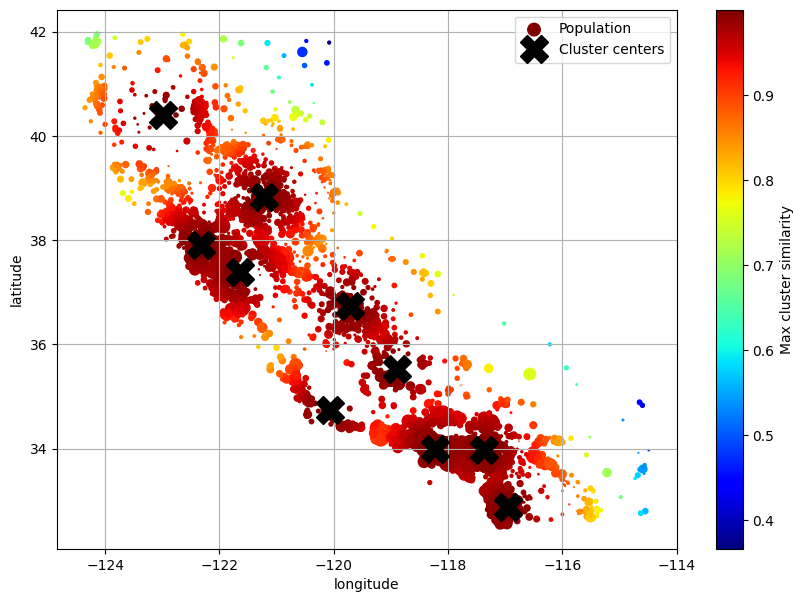

In [57]:
housing_renamed = housing.copy()
housing_renamed["Max cluster similarity"] = similarity.max(axis=1)

housing_renamed.plot(
    kind="scatter", x="longitude", y="latitude", grid=True,
    s=housing_renamed["population"] / 100, label="Population",
    c="Max cluster similarity", cmap="jet", colorbar=True,
    legend=True, sharex=False, figsize=(10, 7)
)
centers = custom_simil.kmeans_.cluster_centers_
plt.plot(centers[:, 1], centers[:, 0], "kX", markersize=20, label="Cluster centers")
plt.legend(loc="upper right")
plt.show()

# Transformation pipeline


In [64]:
from sklearn.pipeline import Pipeline,make_pipeline

num_pipeline = Pipeline([("imputer",SimpleImputer(strategy = "median")),
                        ("Standardize",StandardScaler())])



In [59]:
housing_num_prepared = num_pipeline.fit_transform(housing_num)

In [60]:
housing_num_prepared[:2].round(2)

array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94],
       [ 0.6 , -0.7 ,  0.91, -0.31, -0.44, -0.69, -0.37,  1.17]])

In [61]:
df_housing_num_prepared = pd.DataFrame(housing_num_prepared,columns=num_pipeline.get_feature_names_out(),index=housing_num.index)

In [67]:
from sklearn.compose import ColumnTransformer,make_column_selector

num_attribs = ["longitude", "latitude", "housing_median_age", "total_rooms",
"total_bedrooms", "population", "households", "median_income"]
cat_attribs = ["ocean_proximity"]

cat_pipeline = make_pipeline(SimpleImputer(strategy="most_frequent"),
                        OneHotEncoder(handle_unknown="ignore"))

preprocessing = ColumnTransformer([("num",num_pipeline,num_attribs),
                                   ("cat",cat_pipeline,cat_attribs)])

In [66]:
housing_prepared = preprocessing.fit_transform(housing)

In [68]:
def column_ratio(X):
    return X[:, [0]] / X[:, [1]]
def ratio_name(function_transformer, feature_names_in):
    return ["ratio"] # feature names out
def ratio_pipeline():
    return make_pipeline(SimpleImputer(strategy="median"),
                         FunctionTransformer(column_ratio, feature_names_out=ratio_name),
                         StandardScaler())
log_pipeline = make_pipeline(SimpleImputer(strategy="median"),
                             FunctionTransformer(np.log, feature_names_out="one-to-one"),
                             StandardScaler())
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)

default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"),StandardScaler())

preprocessing = ColumnTransformer([("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
                                   ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
                                   ("people_per_house", ratio_pipeline(), ["population", "households"]),
                                   ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population","households", "median_income"]),
                                   ("geo", cluster_simil, ["latitude", "longitude"]),
                                   ("cat", cat_pipeline, make_column_selector(dtype_include=object)),],remainder=default_num_pipeline)

# now we can train some model

In [69]:
housing_prepared = preprocessing.fit_transform(housing)


In [72]:
housing_prepared.shape

(16512, 24)

In [73]:
preprocessing.get_feature_names_out()

array(['bedrooms__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'geo__Cluster 0 similarity',
       'geo__Cluster 1 similarity', 'geo__Cluster 2 similarity',
       'geo__Cluster 3 similarity', 'geo__Cluster 4 similarity',
       'geo__Cluster 5 similarity', 'geo__Cluster 6 similarity',
       'geo__Cluster 7 similarity', 'geo__Cluster 8 similarity',
       'geo__Cluster 9 similarity', 'cat__ocean_proximity_<1H OCEAN',
       'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND',
       'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN',
       'remainder__housing_median_age'], dtype=object)

In [75]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing,LinearRegression())

lin_reg.fit(housing,housing_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x000...
                                                   'median_income']),
                                                 ('geo',
                                                  ClusterSimilarity(random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x000002BFA52C12B0>)])),
                ('linearregression', LinearRegression())])

In [76]:
housing_predicction  = lin_reg.predict(housing)


In [77]:
housing_predicction[:5].round(-2)

array([246000., 372700., 135700.,  91400., 330900.])

In [79]:
housing_labels.iloc[:5].values


array([458300., 483800., 101700.,  96100., 361800.])

In [80]:
from sklearn.metrics import root_mean_squared_error

lin_rmse = root_mean_squared_error(housing_labels,housing_predicction)
lin_rmse

68972.88910758478

In [81]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = make_pipeline(preprocessing,DecisionTreeRegressor())

In [82]:
tree_reg.fit(housing,housing_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x000...
                                                   'median_income']),
                                                 ('geo',
                                                  ClusterSimilarity(random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x000002BFA52C12B0>)])),
                ('decisiontreeregressor', DecisionTreeRegressor())])

In [83]:
housing_predicction = tree_reg.predict(housing)

In [84]:
tree_rmse = root_mean_squared_error(housing_labels,housing_predicction)

In [85]:
tree_rmse

0.0

# using cross valation 

In [87]:
from sklearn.model_selection import cross_val_score

tree_rmses = cross_val_score(tree_reg,housing,housing_labels,
                             scoring="neg_root_mean_squared_error",cv = 10)

In [89]:
pd.Series(tree_rmses).describe()

count       10.000000
mean    -66091.402582
std        910.977323
min     -67795.785324
25%     -66204.789124
50%     -65891.320670
75%     -65536.974289
max     -65055.493526
dtype: float64

In [90]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = make_pipeline(preprocessing,RandomForestRegressor())

forest_rmses = cross_val_score(forest_reg,housing,housing_labels,
                               scoring="neg_root_mean_squared_error",cv = 10)

In [92]:
pd.Series(forest_rmses).describe()

count       10.000000
mean    -47210.139476
std        958.131984
min     -49373.484347
25%     -47507.268134
50%     -47265.972216
75%     -46636.027173
max     -45877.109065
dtype: float64

# Fine tuning Model 

# using Randomize search 

In [94]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
full_pipeline = Pipeline([("preprocessing", preprocessing),
                          ("random_forest", RandomForestRegressor(random_state=42)),])

param_decribe = {'preprocessing__geo__n_clusters': randint(low = 2 , high = 50),
                 'random_forest__max_features': randint(low = 2 , high = 20)}

rnd_search = RandomizedSearchCV(full_pipeline,param_distributions=param_decribe, n_iter=10,cv=3,
                                scoring="neg_root_mean_squared_error",random_state=42)

rnd_search.fit(housing,housing_labels)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                           SimpleImputer(strategy='median')),
                                                                                          ('standardscaler',
                                                                                           StandardScaler())]),
                                                                transformers=[('bedrooms',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('functiontransformer',
                                                                                                FunctionTransformer(feature_names_...
                                             ('random_forest',
                                              RandomForestRegressor(random_state=42))]),
                   param_distributions={'preprocessing__geo__n_clusters': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000002BFBB31DE50>,
                                        'random_forest__max_features': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000002BFA1C128B0>},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [95]:
final_model = rnd_search.best_estimator_

In [96]:
feature_importances = final_model["random_forest"].feature_importances_
feature_importances.round(2)

array([0.06, 0.05, 0.04, 0.01, 0.01, 0.01, 0.01, 0.2 , 0.02, 0.02, 0.01,
       0.02, 0.01, 0.  , 0.01, 0.01, 0.01, 0.02, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.  , 0.02, 0.01, 0.01, 0.  , 0.01, 0.01, 0.01,
       0.02, 0.01, 0.01, 0.01, 0.01, 0.03, 0.01, 0.02, 0.01, 0.02, 0.01,
       0.02, 0.02, 0.01, 0.01, 0.01, 0.01, 0.  , 0.01, 0.  , 0.08, 0.  ,
       0.  , 0.  , 0.01])

In [97]:
sorted(zip(feature_importances,final_model["preprocessing"].get_feature_names_out()),
       reverse = True)

[(np.float64(0.19983176237588635), 'log__median_income'),
 (np.float64(0.08410016909363154), 'cat__ocean_proximity_INLAND'),
 (np.float64(0.06295142826448782), 'bedrooms__ratio'),
 (np.float64(0.04752236406567198), 'rooms_per_house__ratio'),
 (np.float64(0.044423848909684836), 'people_per_house__ratio'),
 (np.float64(0.031101529722933983), 'geo__Cluster 30 similarity'),
 (np.float64(0.024035341190189075), 'geo__Cluster 34 similarity'),
 (np.float64(0.02261797395060412), 'geo__Cluster 37 similarity'),
 (np.float64(0.022462287256507518), 'geo__Cluster 25 similarity'),
 (np.float64(0.02177973555992273), 'geo__Cluster 9 similarity'),
 (np.float64(0.019750924290288588), 'geo__Cluster 36 similarity'),
 (np.float64(0.019012205186074396), 'geo__Cluster 0 similarity'),
 (np.float64(0.016705550915951658), 'geo__Cluster 32 similarity'),
 (np.float64(0.01593531637345587), 'geo__Cluster 3 similarity'),
 (np.float64(0.015109089482622264), 'geo__Cluster 18 similarity'),
 (np.float64(0.015050863162345

# Testing 

In [99]:
x_test = start_test_set.drop("median_house_value",axis=1)
y_test = start_test_set["median_house_value"].copy()

final_prediction = final_model.predict(x_test)

final_rmse = root_mean_squared_error(y_test,final_prediction)
print(final_rmse)

41493.47017100527


In [100]:
from scipy import stats
def rmse(squared_errors):
    return np.sqrt(np.mean(squared_errors))
confidence = 0.95
squared_errors = (final_prediction - y_test) ** 2
boot_result = stats.bootstrap([squared_errors], rmse,
                              confidence_level=confidence, random_state=42)
rmse_lower, rmse_upper = boot_result.confidence_interval

# launch monitor and test 

In [101]:
import joblib 

joblib.dump(final_model,"Predicting california house prices")

['Predicting california house prices']